# Machine Learning-Based Non-Performing Loan Risk Prediction for Sri Lankan Banking Data

## Problem Definition

The objective of this project is to develop a machine learning model that can predict whether a bank loan is likely to become Performing or Non-Performing.

This is a binary classification problem.

The project uses a Sri Lankan banking loan dataset and compares multiple machine learning models to identify the most suitable model for Non-Performing Loan (NPL) risk prediction.

In [131]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier
)

from xgboost import XGBClassifier



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

import joblib

import shap

In [132]:

# Load dataset and keep "None" as a valid text category

df = pd.read_excel(
    "BankDataset NPL.xlsx",
    sheet_name="Sheet1",
    keep_default_na=False
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1806, 11)


,ProductID,Loan ID,Product,LoanBalance,Age,Income,Status,CustomerCategory,Gender,Education,CRIB Category
0,1,CUST-00299,Housing Loan,3675464,24,234690,Performing,Business Medium,Male,Degree,D
1,2,CUST-00986,Leasing,1691773,57,52097,Performing,Business Medium,Male,Degree,D
2,3,CUST-00916,Business Loan,4078848,31,452725,Performing,Business Medium,Male,A/L,A
3,4,CUST-00719,Leasing,3852608,47,183226,Performing,Retail,Male,Degree,C
4,4,CUST-01169,Business Loan,92165,28,226824,Performing,Business Small,Male,O/L,B


In [133]:
# Display basic dataset information

df.info()

# Display statistical summary of numerical columns

df.describe()

# Check missing values

df.isnull().sum()

# Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1806 entries, 0 to 1805
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ProductID         1806 non-null   int64 
 1   Loan ID           1806 non-null   object
 2   Product           1806 non-null   object
 3   LoanBalance       1806 non-null   int64 
 4   Age               1806 non-null   int64 
 5   Income            1806 non-null   int64 
 6   Status            1806 non-null   object
 7   CustomerCategory  1806 non-null   object
 8   Gender            1806 non-null   object
 9   Education         1806 non-null   object
 10  CRIB Category     1806 non-null   object
dtypes: int64(4), object(7)
memory usage: 155.3+ KB
Duplicate rows: 0


In [134]:
# Check target class distribution

print(df["Status"].value_counts())

print(
    df["Status"].value_counts(normalize=True) * 100
)

Status
Performing        1605
Non Performing     201
Name: count, dtype: int64
Status
Performing        88.870432
Non Performing    11.129568
Name: proportion, dtype: float64


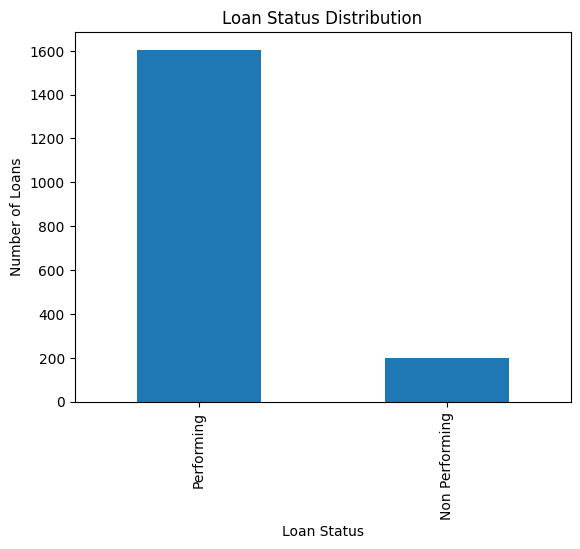

In [135]:
# Visualize target class distribution

df["Status"].value_counts().plot(
    kind="bar"
)

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.show()

In [136]:
# Display unique values in categorical columns

categorical_columns = [
    "Product",
    "CustomerCategory",
    "Gender",
    "Education",
    "CRIB Category"
]

for column in categorical_columns:

    print("\n", column)

    print(
        df[column].value_counts()
    )


 Product
Product
Business Loan    610
Leasing          356
Housing Loan     350
Gold Loan        322
Personal Loan    168
Name: count, dtype: int64

 CustomerCategory
CustomerCategory
Retail             760
Business Small     615
Business Medium    427
PRV                  4
Name: count, dtype: int64

 Gender
Gender
Male      1004
Female     802
Name: count, dtype: int64

 Education
Education
Degree     473
O/L        467
A/L        456
None       408
Masters      1
Diploma      1
Name: count, dtype: int64

 CRIB Category
CRIB Category
E    506
A    348
D    337
B    316
C    299
Name: count, dtype: int64


In [137]:
# Compare loan status by CRIB category

crib_status = pd.crosstab(
    df["CRIB Category"],
    df["Status"]
)

crib_status

# Calculate NPL percentage for each CRIB category

crib_npl_rate = pd.crosstab(
    df["CRIB Category"],
    df["Status"],
    normalize="index"
) * 100

crib_npl_rate

Status,Non Performing,Performing
CRIB Category,,
A,0.000000,100.000000
B,0.000000,100.000000
C,1.337793,98.662207
D,9.198813,90.801187
E,32.806324,67.193676


In [138]:
# Remove identifier columns

df_model = df.drop(
    columns=[
        "ProductID",
        "Loan ID"
    ]
)

df_model.head()

,Product,LoanBalance,Age,Income,Status,CustomerCategory,Gender,Education,CRIB Category
0,Housing Loan,3675464,24,234690,Performing,Business Medium,Male,Degree,D
1,Leasing,1691773,57,52097,Performing,Business Medium,Male,Degree,D
2,Business Loan,4078848,31,452725,Performing,Business Medium,Male,A/L,A
3,Leasing,3852608,47,183226,Performing,Retail,Male,Degree,C
4,Business Loan,92165,28,226824,Performing,Business Small,Male,O/L,B


In [139]:
# Convert target variable to binary values

df_model["Status"] = df_model["Status"].map({
    "Performing": 0,
    "Non Performing": 1
})

df_model["Status"].value_counts()

,count
Status,
0,1605
1,201


In [140]:
# Separate input features and target

X = df_model.drop(
    columns=["Status"]
)

y = df_model["Status"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1806, 8)
Target shape: (1806,)


In [141]:
# Define numerical and categorical features

numerical_features = [
    "LoanBalance",
    "Age",
    "Income"
]

categorical_features = [
    "Product",
    "CustomerCategory",
    "Gender",
    "Education",
    "CRIB Category"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['LoanBalance', 'Age', 'Income']

Categorical features:
['Product', 'CustomerCategory', 'Gender', 'Education', 'CRIB Category']


In [142]:
# Split data into training, validation and test sets

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 1264
Validation samples: 271
Testing samples: 271


In [143]:
# Check class distribution after splitting

print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTest distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
Status
0    88.844937
1    11.155063
Name: proportion, dtype: float64

Validation distribution:
Status
0    88.929889
1    11.070111
Name: proportion, dtype: float64

Test distribution:
Status
0    88.929889
1    11.070111
Name: proportion, dtype: float64


## Feature Preprocessing

The numerical features are standardized using StandardScaler.

Categorical features are transformed using One-Hot Encoding so that machine learning algorithms can process them.

The Education value `None` is treated as a valid category and not as a missing value.

In [144]:
# Numerical preprocessing

numerical_transformer = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# Categorical preprocessing

categorical_transformer = Pipeline(
    steps=[
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# Combine preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

## Random Forest Model

Random Forest is an ensemble learning model that combines multiple decision trees.

It can capture non-linear relationships and interactions between loan characteristics.

Because the target classes are imbalanced, balanced class weights are used to give more importance to the Non-Performing Loan class.

In [145]:
# Create Random Forest pipeline

rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train Random Forest model

rf_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [146]:
# Predict validation data

rf_predictions = rf_model.predict(
    X_val
)

rf_probabilities = rf_model.predict_proba(
    X_val
)[:, 1]

Accuracy: 0.8192
Precision: 0.3137
Recall: 0.5333
F1 Score: 0.3951
ROC-AUC: 0.8632
              precision    recall  f1-score   support

           0       0.94      0.85      0.89       241
           1       0.31      0.53      0.40        30

    accuracy                           0.82       271
   macro avg       0.63      0.69      0.64       271
weighted avg       0.87      0.82      0.84       271



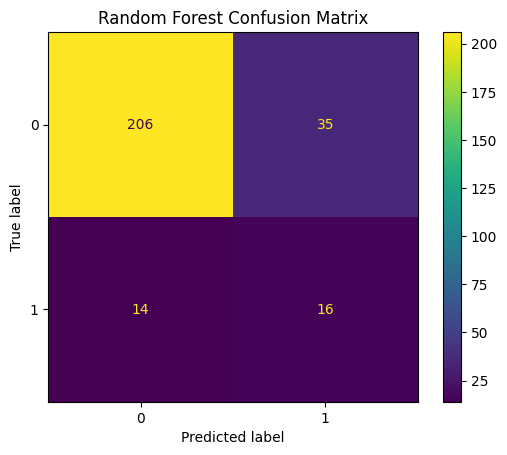

In [147]:
# Evaluate Random Forest

rf_accuracy = accuracy_score(
    y_val,
    rf_predictions
)

rf_precision = precision_score(
    y_val,
    rf_predictions
)

rf_recall = recall_score(
    y_val,
    rf_predictions
)

rf_f1 = f1_score(
    y_val,
    rf_predictions
)

rf_auc = roc_auc_score(
    y_val,
    rf_probabilities
)


print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_auc, 4))

print(
    classification_report(
        y_val,
        rf_predictions
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_predictions
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

## XGBoost Model

XGBoost is a gradient boosting algorithm that builds decision trees sequentially.

Each new tree attempts to correct errors made by the previous trees.

Because the dataset is imbalanced, the positive class weight is adjusted so that Non-Performing Loans receive greater importance during training.

In [148]:
# Calculate class imbalance ratio

negative_count = (
    y_train == 0
).sum()

positive_count = (
    y_train == 1
).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print(
    "Scale Pos Weight:",
    round(scale_pos_weight, 2)
)

Scale Pos Weight: 7.96


In [149]:
# Create XGBoost pipeline

xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            XGBClassifier(
                n_estimators=200,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                eval_metric="logloss",
                random_state=42
            )
        )
    ]
)

# Train XGBoost model

xgb_model.fit(
    X_train,
    y_train
)

# Predict validation data

xgb_predictions = xgb_model.predict(
    X_val
)

xgb_probabilities = xgb_model.predict_proba(
    X_val
)[:, 1]



In [150]:
# Evaluate XGBoost

xgb_accuracy = accuracy_score(
    y_val,
    xgb_predictions
)

xgb_precision = precision_score(
    y_val,
    xgb_predictions
)

xgb_recall = recall_score(
    y_val,
    xgb_predictions
)

xgb_f1 = f1_score(
    y_val,
    xgb_predictions
)

xgb_auc = roc_auc_score(
    y_val,
    xgb_probabilities
)


print("Accuracy:", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall:", round(xgb_recall, 4))
print("F1 Score:", round(xgb_f1, 4))
print("ROC-AUC:", round(xgb_auc, 4))



Accuracy: 0.8413
Precision: 0.3673
Recall: 0.6
F1 Score: 0.4557
ROC-AUC: 0.861


              precision    recall  f1-score   support

           0       0.95      0.87      0.91       241
           1       0.37      0.60      0.46        30

    accuracy                           0.84       271
   macro avg       0.66      0.74      0.68       271
weighted avg       0.88      0.84      0.86       271



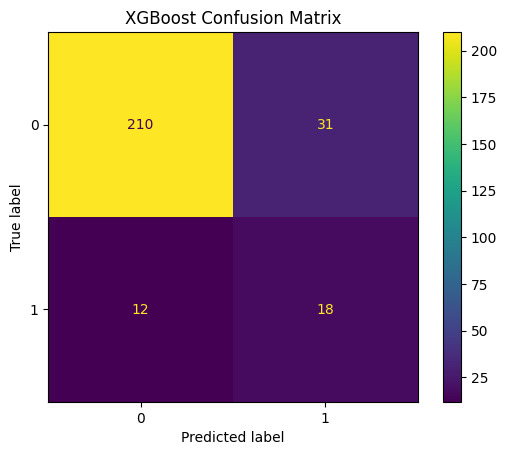

In [151]:
print(
    classification_report(
        y_val,
        xgb_predictions
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    xgb_predictions
)

plt.title(
    "XGBoost Confusion Matrix"
)

plt.show()

##  AdaBoost Model

AdaBoost is a boosting-based ensemble learning algorithm.

It builds a sequence of weak learners, where each new learner gives more attention to observations that were incorrectly classified by previous learners.

AdaBoost was included as a third ensemble model to compare different ensemble learning strategies for the Non-Performing Loan classification problem.

In [152]:
# Create AdaBoost pipeline

ada_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            AdaBoostClassifier(
                n_estimators=200,
                learning_rate=0.05,
                random_state=42
            )
        )
    ]
)

# Train AdaBoost model

ada_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 AdaBoostClassifier(learning_rate=0.05, n_estimators=200,
                                    random_state=42))])

In [153]:
# Predict validation data

ada_predictions = ada_model.predict(
    X_val
)

ada_probabilities = ada_model.predict_proba(
    X_val
)[:, 1]

In [154]:
# Evaluate AdaBoost

ada_accuracy = accuracy_score(
    y_val,
    ada_predictions
)

ada_precision = precision_score(
    y_val,
    ada_predictions,
    zero_division=0
)

ada_recall = recall_score(
    y_val,
    ada_predictions
)

ada_f1 = f1_score(
    y_val,
    ada_predictions
)

ada_auc = roc_auc_score(
    y_val,
    ada_probabilities
)

print("Accuracy:", round(ada_accuracy, 4))
print("Precision:", round(ada_precision, 4))
print("Recall:", round(ada_recall, 4))
print("F1 Score:", round(ada_f1, 4))
print("ROC-AUC:", round(ada_auc, 4))

Accuracy: 0.8893
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.8213


In [155]:
print(
    classification_report(
        y_val,
        ada_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.89      1.00      0.94       241
           1       0.00      0.00      0.00        30

    accuracy                           0.89       271
   macro avg       0.44      0.50      0.47       271
weighted avg       0.79      0.89      0.84       271



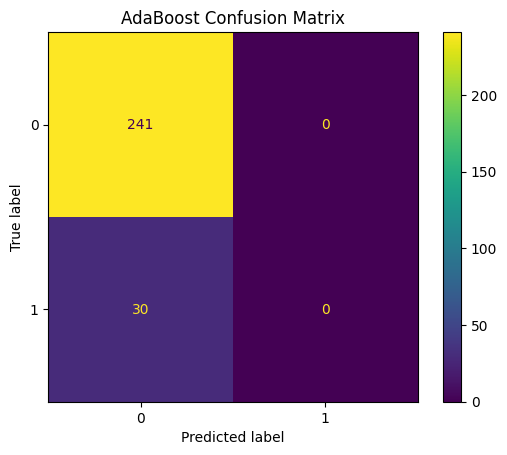

In [156]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    ada_predictions
)

plt.title(
    "AdaBoost Confusion Matrix"
)

plt.show()

In [157]:
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "AdaBoost"
    ],
    "Accuracy": [
        rf_accuracy,
        xgb_accuracy,
        ada_accuracy
    ],
    "Precision": [
        rf_precision,
        xgb_precision,
        ada_precision
    ],
    "Recall": [
        rf_recall,
        xgb_recall,
        ada_recall
    ],
    "F1 Score": [
        rf_f1,
        xgb_f1,
        ada_f1
    ],
    "ROC-AUC": [
        rf_auc,
        xgb_auc,
        ada_auc
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.819188,0.313725,0.533333,0.395062,0.863209
1,XGBoost,0.841328,0.367347,0.600000,0.455696,0.860996
2,AdaBoost,0.889299,0.000000,0.000000,0.000000,0.821300


##  Initial Model Comparison

The three ensemble models show different strengths.

- Random Forest achieved moderate Accuracy while maintaining better Recall for the Non-Performing Loan class.
- XGBoost achieved the highest F1 Score among the initial models and provided a better balance between Precision and Recall.
- AdaBoost achieved high overall Accuracy, but it failed to identify Non-Performing Loans effectively, resulting in very low Recall and F1 Score.

Because the dataset is imbalanced, Accuracy alone is not sufficient for selecting the best model.

For this NPL risk prediction problem, special attention is given to Recall and F1 Score because failing to identify an actual Non-Performing Loan is an important risk.

## Model Tuning

A small number of important hyperparameter combinations are tested using the validation set.

The test set is kept untouched until the final evaluation.

In [158]:
# Test a small number of Random Forest settings

rf_tuning_results = []

for n_estimators in [100, 200, 300]:
    for max_depth in [6, 10, 14]:

        model = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor
                ),
                (
                    "model",
                    RandomForestClassifier(
                        n_estimators=n_estimators,
                        max_depth=max_depth,
                        min_samples_split=5,
                        min_samples_leaf=2,
                        class_weight="balanced",
                        random_state=42,
                        n_jobs=-1
                    )
                )
            ]
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        rf_tuning_results.append({
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "Precision": precision_score(
                y_val,
                predictions
            ),
            "Recall": recall_score(
                y_val,
                predictions
            ),
            "F1 Score": f1_score(
                y_val,
                predictions
            )
        })


rf_tuning_df = pd.DataFrame(
    rf_tuning_results
)

rf_tuning_df.sort_values(
    "F1 Score",
    ascending=False
)

best_rf_params = rf_tuning_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]

best_rf_params

,0
n_estimators,100.000000
max_depth,6.000000
Precision,0.295455
Recall,0.866667
F1 Score,0.440678


In [159]:
# Test a small number of XGBoost settings

xgb_tuning_results = []

for n_estimators in [100, 200, 300]:
    for max_depth in [3, 5, 7]:
        for learning_rate in [0.05, 0.1]:

            model = Pipeline(
                steps=[
                    (
                        "preprocessor",
                        preprocessor
                    ),
                    (
                        "model",
                        XGBClassifier(
                            n_estimators=n_estimators,
                            max_depth=max_depth,
                            learning_rate=learning_rate,
                            subsample=0.8,
                            colsample_bytree=0.8,
                            scale_pos_weight=scale_pos_weight,
                            eval_metric="logloss",
                            random_state=42
                        )
                    )
                ]
            )

            model.fit(
                X_train,
                y_train
            )

            predictions = model.predict(
                X_val
            )

            xgb_tuning_results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "Precision": precision_score(
                    y_val,
                    predictions
                ),
                "Recall": recall_score(
                    y_val,
                    predictions
                ),
                "F1 Score": f1_score(
                    y_val,
                    predictions
                )
            })


xgb_tuning_df = pd.DataFrame(
    xgb_tuning_results
)

xgb_tuning_df.sort_values(
    "F1 Score",
    ascending=False
)

best_xgb_params = xgb_tuning_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]

best_xgb_params

,15
n_estimators,300.000000
max_depth,5.000000
learning_rate,0.100000
Precision,0.517241
Recall,0.500000
F1 Score,0.508475


In [160]:
# Test a small number of AdaBoost settings

ada_tuning_results = []

for n_estimators in [50, 100, 200, 300]:
    for learning_rate in [0.01, 0.05, 0.1, 0.5]:

        model = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor
                ),
                (
                    "model",
                    AdaBoostClassifier(
                        n_estimators=n_estimators,
                        learning_rate=learning_rate,
                        random_state=42
                    )
                )
            ]
        )

        model.fit(
            X_train,
            y_train
        )

        predictions = model.predict(
            X_val
        )

        probabilities = model.predict_proba(
            X_val
        )[:, 1]

        ada_tuning_results.append({
            "n_estimators": n_estimators,
            "learning_rate": learning_rate,
            "Precision": precision_score(
                y_val,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val,
                predictions,
                zero_division=0
            ),
            "F1 Score": f1_score(
                y_val,
                predictions,
                zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_val,
                probabilities
            )
        })


ada_tuning_df = pd.DataFrame(
    ada_tuning_results
)

ada_tuning_df.sort_values(
    "F1 Score",
    ascending=False
)

best_ada_params = ada_tuning_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]

best_ada_params


,15
n_estimators,300.000000
learning_rate,0.500000
Precision,0.750000
Recall,0.100000
F1 Score,0.176471
ROC-AUC,0.875519


In [161]:
# Combine training and validation data

X_train_final = pd.concat(
    [X_train, X_val]
)

y_train_final = pd.concat(
    [y_train, y_val]
)

print(
    "Final training samples:",
    len(X_train_final)
)

print(
    "Final test samples:",
    len(X_test)
)

Final training samples: 1535
Final test samples: 271


In [162]:
# Train final Random Forest

final_rf = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=int(
                    best_rf_params[
                        "n_estimators"
                    ]
                ),
                max_depth=int(
                    best_rf_params[
                        "max_depth"
                    ]
                ),
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

final_rf.fit(
    X_train_final,
    y_train_final
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=6,
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_jobs=-1, random_state=42))])

In [163]:
# Recalculate class weight using final training data

negative_count_final = (
    y_train_final == 0
).sum()

positive_count_final = (
    y_train_final == 1
).sum()

scale_pos_weight_final = (
    negative_count_final /
    positive_count_final
)

In [164]:

# Train final XGBoost

final_xgb = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            XGBClassifier(
                n_estimators=int(
                    best_xgb_params[
                        "n_estimators"
                    ]
                ),
                max_depth=int(
                    best_xgb_params[
                        "max_depth"
                    ]
                ),
                learning_rate=float(
                    best_xgb_params[
                        "learning_rate"
                    ]
                ),
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=
                    scale_pos_weight_final,
                eval_metric="logloss",
                random_state=42
            )
        )
    ]
)

final_xgb.fit(
    X_train_final,
    y_train_final
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 XGBClassifier(base_score=None, booster=None, ca...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [165]:
# Train final AdaBoost model

final_ada = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            AdaBoostClassifier(
                n_estimators=int(
                    best_ada_params[
                        "n_estimators"
                    ]
                ),
                learning_rate=float(
                    best_ada_params[
                        "learning_rate"
                    ]
                ),
                random_state=42
            )
        )
    ]
)

final_ada.fit(
    X_train_final,
    y_train_final
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 AdaBoostClassifier(learning_rate=0.5, n_estimators=300,
                                    random_state=42))])

In [166]:
# Function to evaluate a model on the test set

def evaluate_model(
    model,
    model_name
):

    predictions = model.predict(
        X_test
    )

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions
        ),
        "Recall": recall_score(
            y_test,
            predictions
        ),
        "F1 Score": f1_score(
            y_test,
            predictions
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        )
    }

In [167]:
# Final model comparison

final_results = [
    evaluate_model(
        final_rf,
        "Random Forest"
    ),
    evaluate_model(
        final_xgb,
        "XGBoost"
    ),
    evaluate_model(
        final_ada,
        "AdaBoost"
    )
]

final_comparison = pd.DataFrame(
    final_results
)

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.826568,0.365079,0.766667,0.494624,0.911203
1,XGBoost,0.878229,0.451613,0.466667,0.459016,0.869986
2,AdaBoost,0.900369,1.000000,0.100000,0.181818,0.914246


##  Final Model Selection

The final test results show different strengths among the three ensemble models.

- AdaBoost achieved the highest Accuracy and ROC-AUC, but its Recall for Non-Performing Loans was very low.
- XGBoost achieved higher Accuracy than Random Forest, but its Recall was lower.
- Random Forest achieved the highest F1 Score and the highest Recall among the three models while maintaining a strong ROC-AUC score.

In this problem, identifying actual Non-Performing Loans is important because a false negative represents a risky loan incorrectly predicted as Performing.

Therefore, Random Forest was selected as the final model because it provides the best balance between Recall, F1 Score, and overall discrimination performance.

              precision    recall  f1-score   support

           0       0.97      0.83      0.90       241
           1       0.37      0.77      0.49        30

    accuracy                           0.83       271
   macro avg       0.67      0.80      0.69       271
weighted avg       0.90      0.83      0.85       271



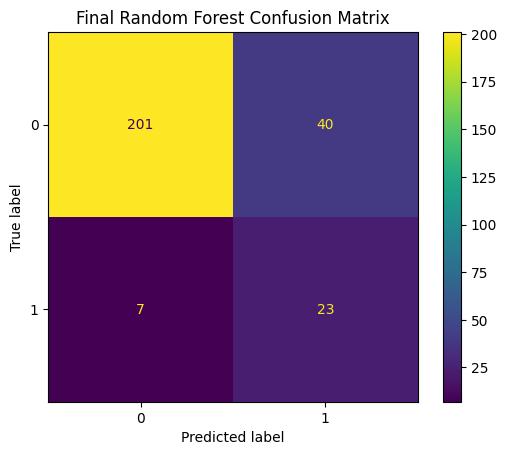

In [168]:
final_rf_predictions = final_rf.predict(
    X_test
)

final_rf_probabilities = final_rf.predict_proba(
    X_test
)[:, 1]

print(
    classification_report(
        y_test,
        final_rf_predictions
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_rf_predictions
)

plt.title(
    "Final Random Forest Confusion Matrix"
)

plt.show()

## Feature Importance

Feature importance is used to identify which transformed input features have the greatest influence on the Random Forest model.

In [169]:
preprocessor_fitted = final_rf.named_steps[
    "preprocessor"
]

encoded_features = preprocessor_fitted.named_transformers_[
    "cat"
].named_steps[
    "encoder"
].get_feature_names_out(
    categorical_features
)

all_feature_names = (
    numerical_features
    + list(encoded_features)
)

rf_classifier = final_rf.named_steps[
    "model"
]

feature_importance = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
23,CRIB Category_E,0.331785
19,CRIB Category_A,0.132001
20,CRIB Category_B,0.121398
21,CRIB Category_C,0.076847
0,LoanBalance,0.073138
2,Income,0.072759
1,Age,0.045221
22,CRIB Category_D,0.036622
3,Product_Business Loan,0.018939
9,CustomerCategory_Business Small,0.012771


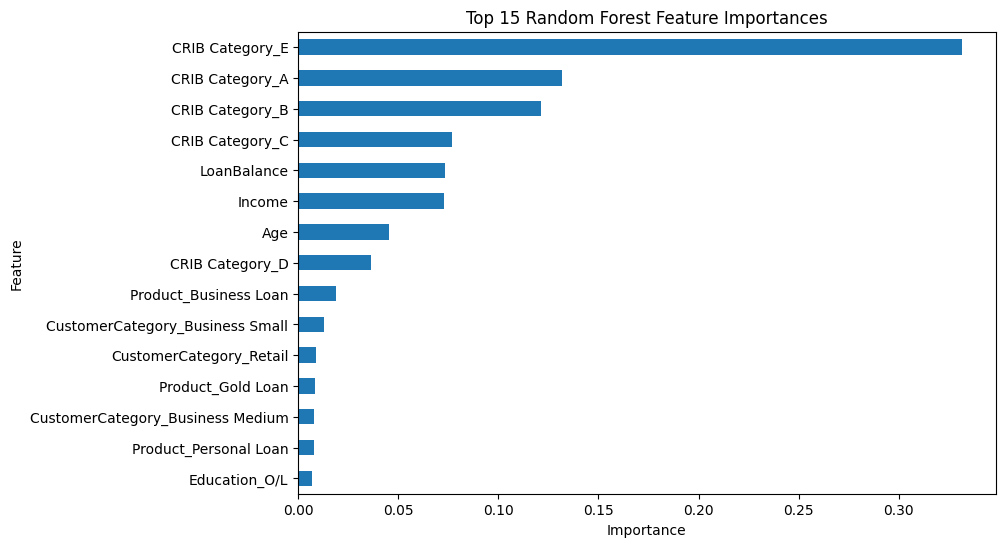

In [170]:
top_features = feature_importance.head(15)

top_features.sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 6)
)

plt.title(
    "Top 15 Random Forest Feature Importances"
)

plt.xlabel(
    "Importance"
)

plt.show()

## SHAP Model Explainability

SHAP is used to explain how individual features contribute to the predictions made by the selected Random Forest model.

This provides additional interpretability beyond standard feature importance.

In [171]:
X_test_transformed = final_rf.named_steps[
    "preprocessor"
].transform(
    X_test
)

feature_names = final_rf.named_steps[
    "preprocessor"
].get_feature_names_out()

rf_estimator = final_rf.named_steps[
    "model"
]

explainer = shap.TreeExplainer(
    rf_estimator
)

shap_values = explainer.shap_values(
    X_test_transformed
)

print(
    type(shap_values)
)

print(
    np.array(shap_values).shape
)

<class 'numpy.ndarray'>
(271, 24, 2)


In [172]:
# SHAP values for class 1 = Non-Performing Loan

shap_values_npl = shap_values[:, :, 1]

print(
    "SHAP values shape for NPL class:",
    shap_values_npl.shape
)

SHAP values shape for NPL class: (271, 24)


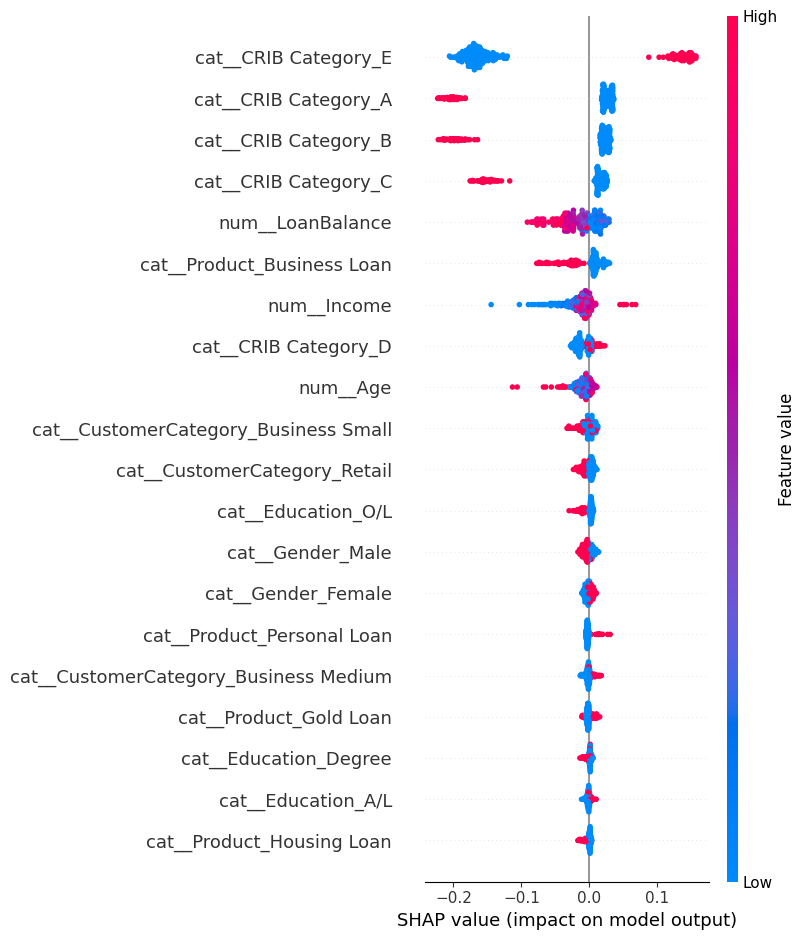

In [173]:
# SHAP summary plot for NPL class

shap.summary_plot(
    shap_values_npl,
    X_test_transformed,
    feature_names=feature_names
)

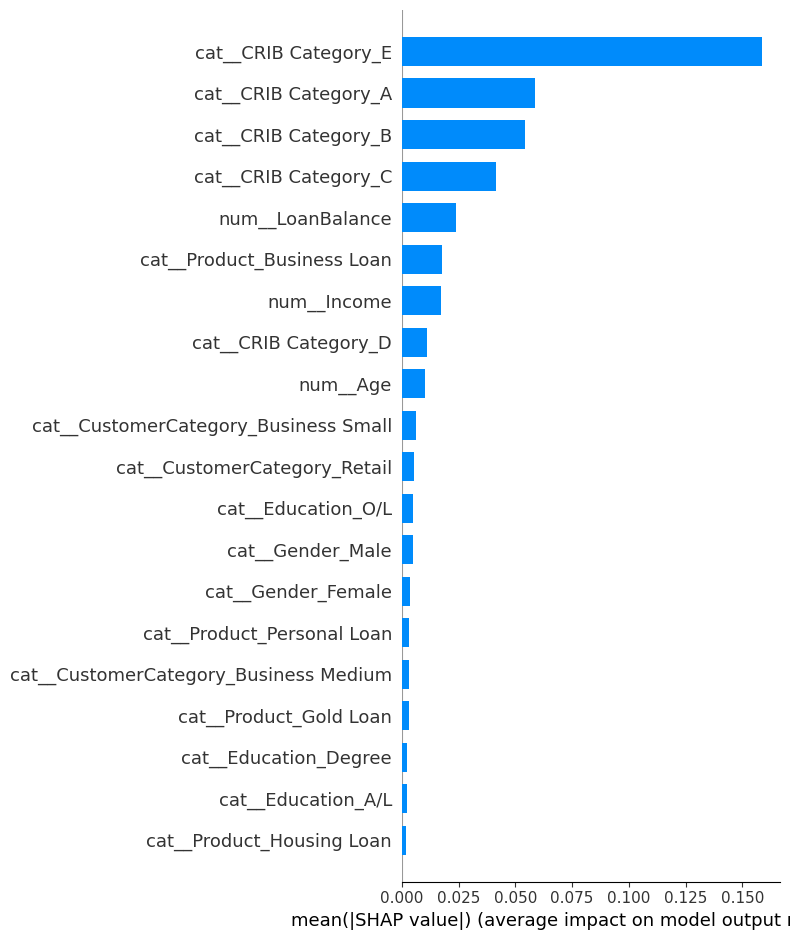

In [174]:
# SHAP feature importance bar plot

shap.summary_plot(
    shap_values_npl,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

### SHAP Interpretation

The SHAP analysis provides an explanation of how the input features influence the Random Forest predictions.

The SHAP summary plot shows the relative contribution of each transformed feature to the prediction of the Non-Performing Loan class.

Features with larger absolute SHAP values have a stronger influence on the model prediction.

The SHAP analysis complements the Random Forest feature importance analysis by showing not only which features are important, but also how they influence individual predictions.

In [175]:
# Select one test record for individual explanation

sample_index = 0

sample_original = X_test.iloc[
    sample_index
]

sample_original

,1200
Product,Leasing
LoanBalance,3379056
Age,59
Income,61590
CustomerCategory,Retail
Gender,Male
Education,O/L
CRIB Category,D


In [176]:
# Prediction for selected record

sample_data = X_test.iloc[
    [sample_index]
]

sample_prediction = final_rf.predict(
    sample_data
)[0]

sample_probability = final_rf.predict_proba(
    sample_data
)[0][1]

print(
    "Prediction:",
    "Non-Performing" if sample_prediction == 1 else "Performing"
)

print(
    "NPL Probability Estimate:",
    round(
        sample_probability * 100,
        2
    ),
    "%"
)

Prediction: Performing
NPL Probability Estimate: 25.01 %


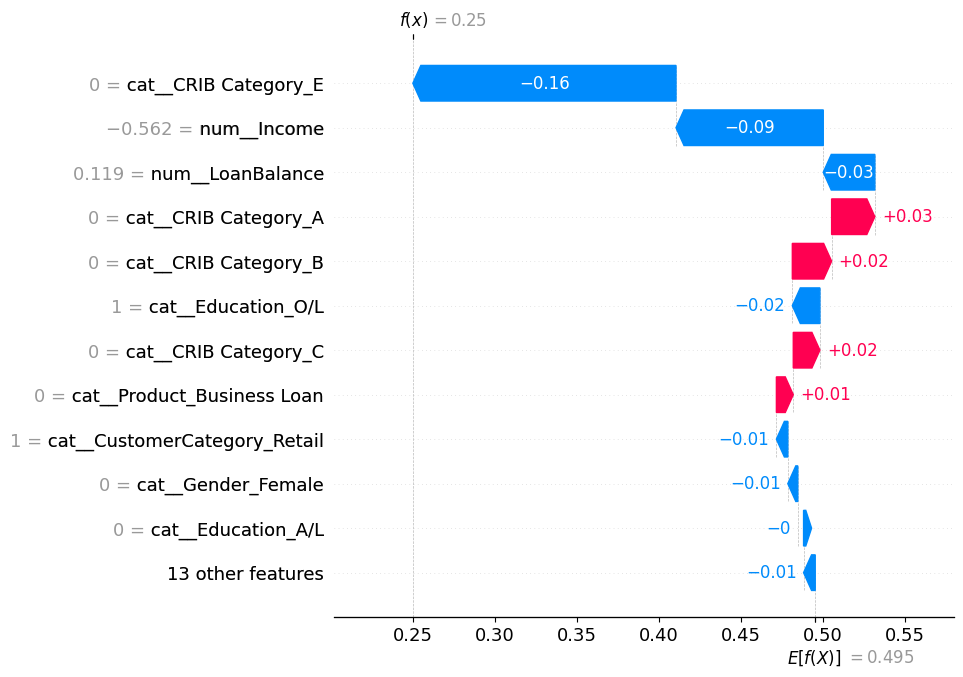

In [177]:
# SHAP explanation for one test record

sample_explanation = shap.Explanation(
    values=shap_values_npl[sample_index],
    base_values=explainer.expected_value[1],
    data=X_test_transformed[sample_index],
    feature_names=feature_names
)

shap.plots.waterfall(
    sample_explanation,
    max_display=12
)

In [178]:

joblib.dump(
    final_rf,
    "npl_risk_model.pkl"
)

joblib.dump(
    list(X.columns),
    "model_features.pkl"
)

final_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print(
    "Model and supporting files saved successfully."
)

Model and supporting files saved successfully.


## Conclusion

This project developed a machine learning solution for predicting Non-Performing Loan risk using Sri Lankan banking data.

Three ensemble machine learning models were compared:

- Random Forest
- XGBoost
- AdaBoost

The models were evaluated using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

Although AdaBoost achieved the highest overall Accuracy, its Recall for the Non-Performing Loan class was very low. XGBoost achieved strong Accuracy but had lower Recall than Random Forest.

Random Forest achieved the highest Recall and F1 Score among the three final models while maintaining a strong ROC-AUC score. Therefore, Random Forest was selected as the final model.

Feature Importance and SHAP analysis were used to interpret the selected model and understand how different loan and customer characteristics influenced the predictions.

The final model was also used to perform inference on a new loan record and was saved for integration with a Streamlit dashboard.

This project demonstrates a complete machine learning workflow including local problem identification, data analysis, preprocessing, ensemble model development, hyperparameter tuning, model comparison, explainability, inference, and deployment preparation.